In [3]:
import networkx as nx
import pandas as pd
import torch
import pickle
from collections import defaultdict
import re
from tqdm import tqdm

## 1. extract protein embedddings

In [7]:
def load_graph(filepath):
    with open(filepath, 'rb') as f:
        G = pickle.load(f)
    print(f"Load graph with {G.number_of_nodes()} nodes and {G.number_of_edges()} edges")
    return G

In [8]:
def get_protein_embeddings(graph_path, embeddings_path):
    
    G = load_graph(graph_path)
    protein_nodes = []
    for node, attr in G.nodes(data=True):
        # print(node)
        # print(attr)

        if attr.get('label')=='Protein':
            protein_nodes.append(node)
    
    df_embedding = pd.read_csv(embeddings_path, index_col=0)
    embeddings = df_embedding[df_embedding.index.isin(protein_nodes)]
    return embeddings

In [9]:
graph_path = "../../EdgeAssignmentTask/neighborhood_selection/results/pykeen_kge/AD_KG/G_merge_AD_KG_healthy.pkl"
embedding_path = "../../EdgeAssignmentTask/neighborhood_selection/results/pykeen_kge/AD_KG/embedding.csv"

embeddings = get_protein_embeddings(graph_path, embeddings_path=embedding_path)
embeddings

Load graph with 7820 nodes and 24461 edges


,Component_1,Component_2,Component_3,Component_4,Component_5,Component_6,Component_7,Component_8,Component_9,Component_10,...,Component_247,Component_248,Component_249,Component_250,Component_251,Component_252,Component_253,Component_254,Component_255,Component_256
"p(CHEBI:""amyloid-beta polypeptide 42"")",0.758013,0.840315,-0.668380,-1.035402,-0.789033,-0.728752,0.825263,-0.854532,-0.810170,-0.730315,...,0.855348,0.794728,-1.128072,0.683695,0.757491,0.674301,0.778190,-0.480189,-0.709318,-0.773411
"p(CHEBI:""amyloid-beta"")",1.043870,-0.834350,-0.841579,-1.001115,0.801758,-0.704465,-0.875370,0.759820,0.944811,-0.843524,...,-0.932681,-0.758649,0.860691,-0.942356,-0.402936,-0.817344,-0.750184,0.695617,0.756227,0.809849
"p(CHEBI:""cholesterol"")",0.937147,0.668329,0.832295,0.876850,-0.852169,-0.847930,1.010515,-0.859997,0.894277,0.614237,...,0.785711,-0.753898,0.745773,-0.737422,0.917765,-0.788705,0.734749,-0.624139,0.817243,-0.970822
"p(CONSO:""APP C-terminally truncated carboxyl-terminal fragments"")",-0.780988,-0.725275,0.698186,-0.674514,-0.924527,-0.820003,-0.923528,0.846194,-0.799977,-1.044326,...,-0.638000,0.697619,-0.870310,0.845823,0.778717,0.831123,-0.708195,-0.769474,0.773794,-0.828740
"p(CONSO:""CDK5R1 p25"")",-0.770664,0.953485,-0.899404,-0.753100,-0.843237,0.836364,-1.024903,0.899582,0.998048,-0.897110,...,0.801592,0.872431,0.464196,-0.923467,0.900340,0.831191,0.917495,0.907396,-0.898288,0.849592
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"p(UniProtKB:""VLDLR_RAT"")",-1.787064,0.306884,-0.289652,-0.335025,-0.443236,0.562618,0.740884,-0.000010,-0.148936,-0.386686,...,0.000003,-0.037486,-0.456205,0.093065,0.296204,0.039868,0.205819,-0.152106,-0.714035,0.035269
"p(UniProtKB:""VLDLR_RAT"",var(""O-linked glycosylation domain_del""))",-2.667995,0.020478,0.318636,-0.662750,-0.014724,-0.282342,-0.305713,0.000931,-0.864058,-0.090317,...,0.003826,1.357807,-1.806617,0.741286,-0.587851,-0.252025,-0.217627,-0.025474,-0.008831,0.069365
"p(UniProtKB:""VPS35_HUMAN"")",-0.816781,-0.831345,0.926868,0.881158,0.832174,-0.879603,0.803383,0.679378,-0.854523,0.863227,...,0.913135,0.746436,0.309258,0.415493,0.835118,0.847702,-0.833886,-0.873864,0.853969,-0.921434
"p(UniProtKB:""VTDB_MOUSE"")",-0.846653,0.017614,0.533697,0.376766,0.218488,-0.245668,2.574210,0.054071,0.081699,0.375207,...,-0.005031,0.147928,-1.221923,0.287658,-0.025344,0.034736,0.051468,-0.063994,0.034525,-0.796880


## 2. create patient-protein network
+ patient features: gene expression
+ proteins features: embeddings
+ edge_weight: normalized expression value
+ edge_type: with/without specifying disease/control

#### Generate sample scoring

In [10]:
import sys
import os

# Get the path to the 'root' directory
root_path = os.path.abspath(os.path.join(os.getcwd(), '..', '..'))

# Add root to the system path
if root_path not in sys.path:
    sys.path.append(root_path)

# Now can import function from upper-folder
from data_processing.sample_scoring import do_radical_search

In [30]:
# normalize expression data
def minmax_normalize_exp(exp_df):
    if exp_df.shape[0] > exp_df.shape[1]:
        exp_df = exp_df.transpose()
    
    # drop genes with no variation
    exp_df = exp_df.loc[:, exp_df.std() > 0]
    # Using median is usually safer for gene expression
    exp_df = exp_df.fillna(exp_df.median())
    # normalize safely
    min_val = exp_df.min()
    max_val = exp_df.max()
    exp_norm = (exp_df - min_val) / (max_val - min_val + 1e-9)
    # final fill-na
    exp_norm = exp_norm.fillna(0)
    return exp_norm, exp_df

In [10]:
class PatientProteinNetworkGenerator():
    def __init__(self):
        self.pattern_hgnc =  r'^p\(HGNC:"([^"]+)"\)$'
        self.pattern_uniprotkb =  r'^p\(UniProtKB:"([^"_%]+)_[A-Z]+"\)$'
        self.pattern_dash = r'(\w+)_HUMAN'
    
    def gene_symbol_extractor(self, text, pattern:str):
        # ^ ensures start at the beginning, $ ensures end at the ')'
        match = re.search(pattern, text)
        if match:
            target = match.group(1)
            return target.upper()
        return None

    def get_symbol_mapping(self, nodes:list):
        """
        Universal helper function to create {gene_symbol: [kg_nodes]} mapping 
        across ad_kg, control_kg, ppi_kg, and prime_kg.
        """
        mapping = defaultdict(list)
        
        for node in nodes:
            # Ensure node is a string and skip empty/complex modifications
            if not isinstance(node, str) or any(x in node for x in ['frag(', 'var(', 'pmod(', 'loc(', ]):
                continue
                
            symbol = None
            
            # Case 1: BEL Namespace syntax (ad_kg & control_kg) -> p(HGNC:"...") or p(UniProtKB:"...")
            if node.startswith('p(') and node.endswith(')'):
                if 'HGNC' in node:
                    symbol = self.gene_symbol_extractor(node, self.pattern_hgnc)
                elif 'UniProtKB' in node:
                    symbol = self.gene_symbol_extractor(node,self.pattern_uniprotkb)
                else:
                    # Fallback for unexpected namespaces inside p(...) like p(FIXME:"...")
                    match = re.search(r'["\']([^"\']+)["\']', node)
                    if match:
                        symbol = match.group(1)
                    #continue

            # Case 2: handle (ppi_kg) -> AL1A1_HUMAN
            elif '_' in node and any(suffix in node for suffix in ['_HUMAN']):
                if 'UniProtKB' not in node and 'HGNC' not in node:
                    symbol = self.gene_symbol_extractor(node, self.pattern_dash)
            else:
                # Case 3: handle Gene/Protein symbols in PrimeKg
                clean_node = node.strip().upper()
                symbol=clean_node

            # Append to our list mapping if a valid symbol was resolved
            if symbol:
                symbol_upper = symbol.upper()
                mapping[symbol_upper].append(node)
                
        return dict(mapping)
    
    def generate(self, KG, 
                 data:pd.DataFrame, 
                 embeddings:pd.DataFrame, 
                 exp:pd.DataFrame, 
                 include_isolated_nodes=False,
                 label_relation=False):

        patient_labels = data['label'].to_dict()
        scores = data.drop(columns=['label'])

        if include_isolated_nodes:
            protein_nodes = [node for node, attr in KG.nodes(data=True) if 'Protein' in attr.get('label')]
        else:
            protein_nodes = embeddings.index.tolist()

        symbol_to_kg_node = self.get_symbol_mapping(list(protein_nodes))
        common_proteins = [s for s in scores.columns if s in symbol_to_kg_node]
        print(f"There are {len(common_proteins)} common Gene Symbols in GE and AD_Healthy_KGs")

        # filter out gene-symbol columns not in KGs, stack them vertically to a series
        sparse_data: pd.Series = scores[common_proteins].stack() # type: ignore
        # filter out gene-symbol columns with ecdf_score=0 (not extremely expressed)
        mask = sparse_data != 0
        radicals = sparse_data.loc[mask]

        summary_df = pd.DataFrame(0, index=data.index, columns=['pos_edges', 'neg_edges'])
        summary_df['pos_linked_nodes'] = [[] for _ in range(len(summary_df))] # Initialize with empty lists
        summary_df['neg_linked_nodes'] = [[] for _ in range(len(summary_df))]
        summary_df['label'] = data['label'].to_list()

        # Add patient nodes to Network
        exp_norm, exp_df = minmax_normalize_exp(exp)

        G = nx.MultiDiGraph()
        relation_map = {1: f'up_reg', -1: f'down_reg'}
        h_relation_map = {1: f'up_reg_h', -1: f'down_reg_h'}
        d_relation_map = {1: f'up_reg_d', -1: f'down_reg_d'}
        # Add protein nodes and edges
        for key, val in tqdm(radicals.items(), total=len(radicals), desc="Linking Samples"):
            if not (isinstance(key, tuple) and len(key) == 2):
            # unexpected index shape — skip or handle explicitly
                continue
            patient, symbol = key

            for protein_node in symbol_to_kg_node[symbol]:
                if label_relation:
                    if 'UniProtKB' in protein_node:
                        rel = h_relation_map.get(int(val))
                    else:
                        rel=d_relation_map.get(int(val))
                else:
                    rel=relation_map.get(int(val))
                
                # add patient node to G
                if not G.has_node(patient):
                    G.add_node(patient, 
                            x=exp_df.loc[patient].values, 
                            y=int(patient_labels[patient]),
                            label='Patient',
                                type='Patient')
                # add protein nodes to G
                if not G.has_node(protein_node):
                    protein_y = 0 if 'UniProtKB' in protein_node else 1 
                    #print(protein_y)
                    try:
                        protein_x = embeddings.loc[protein_node].values
                    except:
                        protein_x = None
                    G.add_node(protein_node,
                            x=protein_x,
                            y=protein_y,
                            label='Protein',
                            type='Protein')
                
                # edge weight: normalized expression value
                raw_weight = exp_norm.at[patient, symbol]
                weight_value = float(raw_weight) # type: ignore
                
                # Use relation as the 'key' for MultiDiGraph edges
                G.add_edge(patient, protein_node, key=rel, relation=rel, weight=weight_value)
                G.add_edge(protein_node, patient, key=f'rev_{rel}', relation=f'rev_{rel}',weight=weight_value)
                
                col = 'pos_edges' if int(val) == 1 else 'neg_edges'
                summary_df.at[patient, col] += 1 # type: ignore
                linked_nodes_col = 'pos_linked_nodes' if int(val)==1 else 'neg_linked_nodes'
                summary_df.at[patient,linked_nodes_col].append(protein_node) # type: ignore
        
        return G, summary_df

In [ ]:
# 2. load exp, design data
exp_df = pd.read_csv("../../data/ADNI/cleaned_gene_expression_data.csv",
                                index_col=0)
design = pd.read_csv("../../data/ADNI/design_with_real_target.tsv",
                     sep='\t',
                     index_col=0)
design['Target'] = design['Old_Target'].map({'Control':0, 'Disease':1})

# 3. sample scoring
data, summary = do_radical_search(data=exp_df,
                                  design=design,
                                  threshold=5,
                                  control=0,
                                  control_based=True)

In [123]:
# script

# 1. prepare protein embeddings
graph_path = "../../EdgeAssignmentTask/neighborhood_selection/results/pykeen_kge/AD_KG/G_merge_AD_KG_healthy.pkl"
kg = load_graph(graph_path)
embedding_path = "../../EdgeAssignmentTask/neighborhood_selection/results/pykeen_kge/AD_KG/embedding.csv"
embeddings = get_protein_embeddings(graph_path, embeddings_path=embedding_path)


# 4. generate network
ppng = PatientProteinNetworkGenerator()
G, summary_df = ppng.generate(KG=kg,
                              data=data, 
                              embeddings=embeddings, 
                              exp=exp_df,
                              include_isolated_nodes=False,
                              label_relation=False)

Load graph with 7820 nodes and 24461 edges
Load graph with 7820 nodes and 24461 edges
There are 634 common Gene Symbols in GE and AD_Healthy_KGs


Linking Samples: 100%|██████████| 47849/47849 [00:30<00:00, 1552.70it/s]


In [124]:
summary_df

,pos_edges,neg_edges,pos_linked_nodes,neg_linked_nodes,label
116_S_1249,26,55,"[p(HGNC:""ABCA1""), p(UniProtKB:""ABCA1_HUMAN""), ...","[p(HGNC:""ACE""), p(HGNC:""APOA2""), p(UniProtKB:""...",0
037_S_4410,69,156,"[p(MGI:""Atg5""), p(UniProtKB:""CAB39_HUMAN""), p(...","[p(HGNC:""ABCA2""), p(HGNC:""ABCA7""), p(UniProtKB...",0
006_S_4153,39,21,"[p(HGNC:""BACE2""), p(MGI:""Bace2""), p(HGNC:""CCND...","[p(UniProtKB:""C1QA_HUMAN""), p(HGNC:""CACNG7""), ...",1
116_S_1232,30,9,"[p(UniProtKB:""ACTN2_HUMAN""), p(HGNC:""ADIPOQ""),...","[p(HGNC:""CDK5R1""), p(HGNC:""CXCL2""), p(UniProtK...",0
099_S_4205,23,58,"[p(UniProtKB:""BAG3_MOUSE""), p(HGNC:""BLMH""), p(...","[p(HGNC:""ABCG2""), p(UniProtKB:""ACTN2_HUMAN""), ...",1
...,...,...,...,...,...
009_S_2381,58,18,"[p(HGNC:""ALB""), p(UniProtKB:""APOA1_HUMAN""), p(...","[p(UniProtKB:""BAG3_MOUSE""), p(HGNC:""BCHE""), p(...",1
053_S_4557,26,18,"[p(HGNC:""ACE""), p(HGNC:""CAPN1""), p(UniProtKB:""...","[p(UniProtKB:""CARD8_HUMAN""), p(HGNC:""CDH2""), p...",1
073_S_4300,19,25,"[p(HGNC:""ANGPT2""), p(MGI:""Atf4""), p(HGNC:""BACE...","[p(HGNC:""ADAM17""), p(HGNC:""CACNG2""), p(HGNC:""C...",1
041_S_4014,126,67,"[p(HGNC:""ABCA7""), p(UniProtKB:""ABCA7_HUMAN""), ...","[p(UniProtKB:""ADAM9_HUMAN""), p(HGNC:""APP""), p(...",0


## Convert networkx to HeteroData

In [11]:
from torch_geometric.data import HeteroData

def paprnetwork_to_hetero_data(G: nx.MultiDiGraph):
    """
    Converts the Patient-Protein network into a PyTorch Geometric HeteroData object.
    .
    """
    print("Starting conversion from NetworkX to HeteroData...")
    data = HeteroData()
    node_mappings = {} # {node_type: {node_name: integer_index}}
    
    # 1. Categorize Nodes and Map Indices
    for node, attrs in G.nodes(data=True):
        n_type = attrs.get('type') or attrs.get('label')
        
        if n_type not in node_mappings:
            node_mappings[n_type] = {}
        
        if node not in node_mappings[n_type]:
            node_mappings[n_type][node] = len(node_mappings[n_type])
   
    # 2. Process ALL Node Types (Initialize x)
    for n_type, mapping in node_mappings.items():

        num_nodes = len(mapping)
        data[n_type].num_nodes = num_nodes

        # Initialize x-feature for all node types (Patient & Protein)
        n_ids = sorted(mapping, key=mapping.get)
        x = torch.tensor([G.nodes[nid]['x'] for nid in n_ids], dtype=torch.float)
        data[n_type].x = x
        data[n_type].y = torch.tensor([G.nodes[nid]['y'] for nid in n_ids], dtype=torch.long)
        
    # 4. Process Edges with separation
    edges_dict = {}
    for u, v, r, attrs in G.edges(keys=True, data=True):
        u_type = G.nodes[u].get('type') or G.nodes[u].get('label')
        v_type = G.nodes[v].get('type') or G.nodes[v].get('label')
        if not isinstance(r, str):
            rel = attrs.get('relation') or attrs.get('rel') or attrs.get('type')
        else:
            rel = r
        
        # Replace double underscores with single ones to satisfy PyG requirements
        safe_rel = str(rel).replace('__', '_')
        
        edge_type = (u_type, safe_rel, v_type)
            
        if edge_type not in edges_dict:
            edges_dict[edge_type] = []
        
        u_idx = node_mappings[u_type][u]
        v_idx = node_mappings[v_type][v]
        edges_dict[edge_type].append([u_idx, v_idx])

    # Finalize Edges in HeteroData
    for etype, content in edges_dict.items():
        data[etype].edge_index = torch.tensor(content, dtype=torch.long).t().contiguous()
    
    print(f"HeteroData created: {len(data.node_types)} node types, {len(data.edge_types)} edge types.")
    
    return data, node_mappings 

/opt/anaconda3/envs/firegnn/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [130]:
data, node_mappings = paprnetwork_to_hetero_data(G=G)

Starting conversion from NetworkX to HeteroData...
HeteroData created: 2 node types, 4 edge types.


In [132]:
node_mappings

{'Patient': {'116_S_1249': 0,
  '037_S_4410': 1,
  '006_S_4153': 2,
  '116_S_1232': 3,
  '099_S_4205': 4,
  '007_S_4467': 5,
  '128_S_0205': 6,
  '003_S_2374': 7,
  '036_S_4491': 8,
  '098_S_4059': 9,
  '031_S_2018': 10,
  '002_S_4654': 11,
  '019_S_4285': 12,
  '141_S_4426': 13,
  '067_S_4072': 14,
  '037_S_4308': 15,
  '041_S_4200': 16,
  '128_S_0200': 17,
  '129_S_4220': 18,
  '018_S_4313': 19,
  '067_S_0257': 20,
  '029_S_1218': 21,
  '141_S_4053': 22,
  '136_S_4408': 23,
  '021_S_2142': 24,
  '114_S_4404': 25,
  '116_S_4167': 26,
  '116_S_4209': 27,
  '073_S_4360': 28,
  '072_S_4539': 29,
  '007_S_2394': 30,
  '128_S_1407': 31,
  '109_S_2200': 32,
  '057_S_1269': 33,
  '022_S_1097': 34,
  '010_S_0420': 35,
  '072_S_2083': 36,
  '014_S_4615': 37,
  '073_S_4259': 38,
  '002_S_1268': 39,
  '024_S_0985': 40,
  '073_S_4382': 41,
  '127_S_0684': 42,
  '067_S_4310': 43,
  '035_S_0156': 44,
  '041_S_4427': 45,
  '127_S_0622': 46,
  '129_S_4396': 47,
  '019_S_4477': 48,
  '002_S_1261': 49,

In [131]:
data

HeteroData(
  Patient={
    num_nodes=744,
    x=[744, 20541],
    y=[744],
  },
  Protein={
    num_nodes=876,
    x=[876, 256],
    y=[876],
  },
  (Patient, up_reg, Protein)={ edge_index=[2, 35097] },
  (Patient, down_reg, Protein)={ edge_index=[2, 31255] },
  (Protein, rev_up_reg, Patient)={ edge_index=[2, 35097] },
  (Protein, rev_down_reg, Patient)={ edge_index=[2, 31255] }
)

### Caveats
+ the BaseKGs have isolated nodes --> no triples after converting nx.graph to pd EdgeList --> no embeddings for those nodes(include proteins) generated
+ I add all protein nodes to the SampleProteinNetwork, but those without embeddings, I give x=None;
+ 

In [108]:
edgelist = pd.read_csv("../../EdgeAssignmentTask/neighborhood_selection/results/pykeen_kge/AD_KG/Edgelist_merge_['PPI_KG', 'Prime_KG', 'AD_KG']_healthy.csv", index_col=0)
train = pd.read_csv(
    "../../EdgeAssignmentTask/neighborhood_selection/results/pykeen_kge/AD_KG/train.edgelist",
    sep=r'\t',
    header=None,
    names=['source', 'relation','target'],
    engine='python'
)

all_nodes = set(edgelist['source']) | set(edgelist['target'])
train_nodes = set(train['source']) | set(train['target'])
missing = len(all_nodes) - len(train_nodes)
missing  # should be ~1287

586

In [112]:
graph_path = "../../EdgeAssignmentTask/neighborhood_selection/results/pykeen_kge/AD_KG/G_merge_AD_KG_healthy.pkl"
ad_h_kg = load_graph(graph_path)

len(list(nx.isolates(ad_h_kg)))

Load graph with 7820 nodes and 24461 edges


701

In [114]:
len(list(nx.isolates(ad_kg)))

705

## Compute Topological features for patients

In [12]:
import numpy as np

def compute_topological_features(G, node_type='Patient',label_homophily=False):
    """
    Compute topological features for patient nodes in the graph.
    
    Args:
        G: NetworkX graph object
        
    Returns:
        dict: Dictionary containing topological features for each node
    """
    print("Computing topological features...")
    
    nodes = [node for node,attr in G.nodes(data=True) if attr.get('label')==node_type]
    degrees = np.array([G.degree(n) for n in nodes])

    avg_neighbor_degrees = nx.average_neighbor_degree(G)
    mean_neighbor_degrees = np.array([avg_neighbor_degrees[n] for n in nodes])
    
    labels = [G.nodes[node].get('y') for node in nodes]
    
    # Centrality measures
    all_degree_centrality = nx.degree_centrality(G)
    degree_centrality = np.array([all_degree_centrality[node] for node in nodes])
    
    # Average edge weight
    avg_edge_weight = []
    for n in nodes:
        if G.degree(n) > 0:
            neibor_weights = []
            for m in G.neighbors(n):
                edge_data_dict = G[n][m] 
                # edge_data_dict looks like: {0: {'weight': 0.1, ...}, 1: {'weight': 0.5, ...}}
                for edge_key, attributes in edge_data_dict.items():
                    weight = attributes.get('weight', 0)
                    neibor_weights.append(weight)
                    #print(weight)
            avg_edge_weight.append(np.mean(neibor_weights))
        else:
            avg_edge_weight.append(0.0)
    avg_edge_weight = np.array(avg_edge_weight)
    
    features = {
            'degrees': degrees,
            'avg_neighborhood_degrees':mean_neighbor_degrees,
            'degree_centrality': degree_centrality,
            'avg_edge_weight': avg_edge_weight
        }

    # Two-hop agreement
    if label_homophily:
        two_hop_agreement = []
        for n in tqdm(nodes, desc="Computing two-hop agreement"):
            d2 = set(nx.single_source_shortest_path_length(G, n, cutoff=2).keys())
            d22 = list(d2)
            for neighbor in d2:
                if neighbor == n or G.nodes()[neighbor].get('label')!= 'Patient':
                    d22.remove(neighbor)
            # print(d22)
            if d22:
                lbls = [G.nodes[m]['y'] for m in d22]
                two_hop_agreement.append(lbls.count(G.nodes[n]['y']) / len(lbls))
            else:
                two_hop_agreement.append(0.0)
        two_hop_agreement = np.array(two_hop_agreement)

        features = {
            'degrees': degrees,
            'avg_neighborhood_degrees':mean_neighbor_degrees,
            'two_hop_agreement': two_hop_agreement,
            'degree_centrality': degree_centrality,
            'avg_edge_weight': avg_edge_weight
        }
    
    return features

In [13]:
G = load_graph("../../EdgeAssignmentTask/neighborhood_selection/results/aggregator/adni/AD_KG/ecdf_2.5/G_adni_Protein.pkl")

Load graph with 1688 nodes and 72200 edges


In [14]:
pa_topo_features = compute_topological_features(
    G, 
    node_type='Patient',
    label_homophily=True,
    )


Computing topological features...


Computing two-hop agreement: 100%|██████████| 744/744 [00:00<00:00, 1410.02it/s]


In [15]:
pr_topo_features = compute_topological_features(
    G, 
    node_type='Protein',
    label_homophily=True,
    )

Computing topological features...


Computing two-hop agreement: 100%|██████████| 944/944 [00:00<00:00, 1046.10it/s]


In [16]:
for name, array in pr_topo_features.items():
    print(name)
    print(array.shape)

degrees
(944,)
avg_neighborhood_degrees
(944,)
two_hop_agreement
(944,)
degree_centrality
(944,)
avg_edge_weight
(944,)


In [17]:
def paprnetwork_to_hetero_data(G: nx.MultiDiGraph, topo_features=True, label_homophily=True):
    """
    Converts the Patient-Protein network into a PyTorch Geometric HeteroData object.
    .
    """
    print("Starting conversion from NetworkX to HeteroData...")
    data = HeteroData()
    node_mappings = {} # {node_type: {node_name: integer_index}}
    
    # 1. Categorize Nodes and Map Indices
    for node, attrs in G.nodes(data=True):
        n_type = attrs.get('type') or attrs.get('label')
        
        if n_type not in node_mappings:
            node_mappings[n_type] = {}
        
        if node not in node_mappings[n_type]:
            node_mappings[n_type][node] = len(node_mappings[n_type])
   
    # 2. Process ALL Node Types (Initialize x)
    for n_type, mapping in node_mappings.items():

        num_nodes = len(mapping)
        data[n_type].num_nodes = num_nodes

        # Initialize x-feature for all node types (Patient & Protein)
        n_ids = sorted(mapping, key=mapping.get)
        x = torch.tensor([G.nodes[nid]['x'] for nid in n_ids], dtype=torch.float)
        data[n_type].x = x
        data[n_type].y = torch.tensor([G.nodes[nid]['y'] for nid in n_ids], dtype=torch.long)

        if topo_features:
            nt_topo_features = compute_topological_features(G, node_type=n_type,label_homophily=label_homophily)

            nt_topo = np.vstack([nt_topo_features[name] for name in nt_topo_features.keys()]).T
            data[n_type].topo_features = torch.tensor(nt_topo,dtype=torch.float)

        
    # 3. Process Edges
    edges_dict = {}
    for u, v, r, attrs in G.edges(keys=True, data=True):
        u_type = G.nodes[u].get('type') or G.nodes[u].get('label')
        v_type = G.nodes[v].get('type') or G.nodes[v].get('label')
        if not isinstance(r, str):
            rel = attrs.get('relation') or attrs.get('rel') or attrs.get('type')
        else:
            rel = r
        
        # Replace double underscores with single ones to satisfy PyG requirements
        safe_rel = str(rel).replace('__', '_')
        
        edge_type = (u_type, safe_rel, v_type)
            
        if edge_type not in edges_dict:
            edges_dict[edge_type] = []
        
        u_idx = node_mappings[u_type][u]
        v_idx = node_mappings[v_type][v]
        edges_dict[edge_type].append([u_idx, v_idx])

    # Finalize Edges in HeteroData
    for etype, content in edges_dict.items():
        data[etype].edge_index = torch.tensor(content, dtype=torch.long).t().contiguous()
    
    print(f"HeteroData created: {len(data.node_types)} node types, {len(data.edge_types)} edge types.")
    
    return data, node_mappings 

In [18]:
data, node_mappings = paprnetwork_to_hetero_data(G, topo_features=True, label_homophily=True)
data

/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_60675/3691290929.py:28: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /Users/runner/miniforge3/conda-bld/libtorch_1719361045918/work/torch/csrc/utils/tensor_new.cpp:277.)
  x = torch.tensor([G.nodes[nid]['x'] for nid in n_ids], dtype=torch.float)


Starting conversion from NetworkX to HeteroData...
Computing topological features...


Computing two-hop agreement: 100%|██████████| 744/744 [00:00<00:00, 1154.42it/s]


Computing topological features...


Computing two-hop agreement: 100%|██████████| 944/944 [00:00<00:00, 1061.76it/s]


HeteroData created: 2 node types, 8 edge types.


HeteroData(
  Patient={
    num_nodes=744,
    x=[744, 20541],
    y=[744],
    topo_features=[744, 5],
  },
  Protein={
    num_nodes=944,
    x=[944, 256],
    y=[944],
    topo_features=[944, 5],
  },
  (Patient, down_reg_d, Protein)={ edge_index=[2, 11407] },
  (Patient, down_reg_h, Protein)={ edge_index=[2, 5025] },
  (Patient, up_reg_d, Protein)={ edge_index=[2, 13531] },
  (Patient, up_reg_h, Protein)={ edge_index=[2, 6137] },
  (Protein, rev_down_reg_d, Patient)={ edge_index=[2, 11407] },
  (Protein, rev_up_reg_d, Patient)={ edge_index=[2, 13531] },
  (Protein, rev_down_reg_h, Patient)={ edge_index=[2, 5025] },
  (Protein, rev_up_reg_h, Patient)={ edge_index=[2, 6137] }
)

In [19]:
data['Patient'].topo_features

tensor([[1.0400e+02, 3.8750e+01, 3.3935e-01, 6.1648e-02, 2.7091e-01],
        [3.0600e+02, 3.8176e+01, 3.5294e-01, 1.8139e-01, 3.4858e-01],
        [7.6000e+01, 4.3816e+01, 6.6402e-01, 4.5050e-02, 4.7895e-01],
        ...,
        [4.6000e+01, 4.2565e+01, 6.6743e-01, 2.7267e-02, 3.1591e-01],
        [2.2800e+02, 3.7123e+01, 3.4938e-01, 1.3515e-01, 5.8567e-01],
        [1.0800e+02, 4.0685e+01, 6.7598e-01, 6.4019e-02, 6.2495e-01]])

### Check dataset

+ ADNI

In [53]:
exp_path = "../../data/ADNI/cleaned_gene_expression_data.csv"
design_path = "../../data/ADNI/design_with_real_target.tsv"
exp_df = pd.read_csv(exp_path,index_col=0)
design = pd.read_csv(design_path,
                    sep='\t',
                    index_col=0)
design['Target'] = design['Old_Target'].map({'Control':0, 'Disease':1})


In [54]:
exp_df

,116_S_1249,037_S_4410,006_S_4153,116_S_1232,099_S_4205,007_S_4467,128_S_0205,003_S_2374,036_S_4491,098_S_4059,...,082_S_4339,022_S_2379,014_S_4668,130_S_0289,141_S_4456,009_S_2381,053_S_4557,073_S_4300,041_S_4014,007_S_0101
gene,,,,,,,,,,,,,,,,,,,,,
A1BG,3.6510,3.1830,3.2780,3.3710,3.3580,3.50400,3.19400,3.00200,3.85500,3.59400,...,3.65500,3.34500,3.33000,3.3680,3.66500,3.30200,3.4030,3.53000,3.53200,3.2980
A1CF,2.2865,2.1230,2.3545,2.3725,2.3865,2.56550,2.35600,2.38200,2.59200,2.36950,...,2.44850,2.44100,2.28200,2.2950,2.41300,2.50750,2.3090,2.41550,2.45450,2.4120
A2M,3.0390,3.5430,3.5280,3.8350,3.3920,3.08100,3.14600,3.28100,3.97400,3.51100,...,3.72500,3.44100,3.49700,3.1280,3.28500,3.52400,3.5150,3.65100,3.60900,3.8040
A2ML1,2.3395,2.2085,2.1745,2.1545,2.1720,2.14900,2.12300,2.34900,2.43250,2.22800,...,2.48150,2.24800,2.29650,1.9650,2.30600,2.25250,2.3225,2.07600,2.34950,2.1700
A3GALT2,2.7830,2.3830,2.5930,2.5700,2.6600,2.38700,2.67300,2.48100,2.99800,2.63800,...,2.84900,2.85600,3.15500,2.6220,2.68700,2.87600,3.1060,2.70700,3.08100,2.9750
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZYG11A,1.9045,1.9265,2.2315,2.0545,2.0405,2.10200,1.91050,2.14900,2.12800,2.04150,...,1.98750,1.93450,2.18100,2.0300,2.00150,1.93200,1.9445,2.07950,2.00750,1.9840
ZYG11B,5.3175,5.3880,5.6280,5.4630,5.6475,5.57325,5.56125,5.61125,5.29375,5.40025,...,5.32025,5.52425,5.41125,5.3625,5.25975,5.44275,5.1400,5.38775,5.05725,4.9920
ZYX,9.2190,8.3785,9.1085,9.3210,9.0300,8.96350,8.53450,9.03400,10.08800,9.35650,...,9.87950,9.40300,9.31050,9.1965,9.50600,9.29000,9.8090,9.52150,9.58100,9.9225


In [55]:
design

,Old_Target,Target
FileName,,
116_S_1249,Control,0
037_S_4410,Control,0
006_S_4153,Disease,1
116_S_1232,Control,0
099_S_4205,Disease,1
...,...,...
009_S_2381,Disease,1
053_S_4557,Disease,1
073_S_4300,Disease,1


+ geo

In [63]:
exp_path = "../../data/GEO/GSE33000_ad_hd/GSE33000_exp_2cls.csv"
design_path = "../../data/GEO/GSE33000_ad_hd/GSE33000_meta_2cls.csv"
exp_df = pd.read_csv(exp_path,index_col=0)
if exp_df.shape[0] > exp_df.shape[1]:
    exp_df = exp_df.T

try:
    design = pd.read_csv(design_path,
                        sep='\t',
                        index_col=0)
    design['Target'] = design['Old_Target'].map({'Control':0, 'Disease':1})
except:
    design = pd.read_csv(design_path, index_col=0)
    design['Target'] = design['Target'].map({'Control':0, 'Disease':1})

exp_df

,A1BG,A2M,A2ML1,A3GALT2,A4GALT,A4GNT,AAAS,AACS,AADAC,AADACL1,...,ZXDB,ZXDC,ZYG11B,ZYG11BL,ZYX,ZZEF1,ZZZ3,tcag7.1017,tcag7.216,tcag7.981
GSM1423780,-0.066694,0.023919,-0.031845,0.015204,0.089450,-0.167457,0.023215,0.004379,0.041729,0.074247,...,0.066588,-0.020308,0.080426,-0.057932,0.007106,0.106203,0.063151,0.066667,0.060402,0.023945
GSM1423781,0.054097,-0.012131,-0.030740,0.034282,-0.006780,0.068906,-0.004402,-0.029354,0.003009,-0.035774,...,0.035217,-0.000390,-0.027666,0.033120,0.065091,-0.040029,-0.118265,0.096145,-0.007896,0.022231
GSM1423782,0.025282,0.001929,-0.085577,-0.023002,-0.314342,0.092161,-0.043387,0.069851,0.010428,0.116397,...,0.072900,-0.042220,0.085496,-0.020298,0.040479,-0.146334,-0.027519,0.165024,-0.008110,0.118489
GSM1423783,0.002485,0.034625,-0.066813,-0.018289,0.094836,0.073653,0.073933,-0.043867,0.045298,-0.087155,...,-0.064955,-0.034116,-0.109619,0.029910,0.079794,-0.000814,-0.250529,-0.014006,-0.238408,-0.042106
GSM1423784,-0.092606,0.019591,-0.030884,0.020118,-0.206281,0.050492,-0.003392,0.055446,0.111875,0.152810,...,-0.091836,-0.050365,0.105040,0.052845,-0.013048,0.023013,0.051360,0.054292,0.115933,0.035485
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
GSM1424242,-0.035529,-0.067985,-0.115346,-0.045191,-0.085769,-0.041509,-0.018460,0.108033,0.010502,0.153964,...,-0.017694,-0.130394,0.012196,-0.022353,0.032304,-0.100798,0.016300,0.053928,-0.060836,0.176064
GSM1424243,0.075622,-0.010792,-0.088835,-0.021300,-0.096128,-0.037948,0.038506,0.107594,0.001454,0.062382,...,0.025705,-0.133761,-0.092569,0.121448,0.159210,0.017417,-0.108027,0.072586,0.090821,0.010657
GSM1424244,0.065244,-0.087919,-0.120331,-0.038014,0.068436,-0.003720,0.013911,0.034820,0.105181,0.085700,...,-0.043359,-0.048832,-0.040329,0.001067,0.012171,0.130757,0.016830,0.094532,-0.294262,0.086503
GSM1424245,0.054953,0.072740,-0.094495,-0.028996,-0.039163,-0.066074,0.028088,0.070063,-0.028701,0.052751,...,-0.040056,-0.091335,-0.080240,0.045302,0.084873,0.083839,-0.073553,0.106768,-0.118929,0.061755


In [64]:
design

,Tissue,Sample type,Age,Gender,Disease status,Target
GSM1423780,prefrontal cortex brain,reference,67 yrs,female,Alzheimer's disease,1
GSM1423781,prefrontal cortex brain,reference,88 yrs,male,Alzheimer's disease,1
GSM1423782,prefrontal cortex brain,reference,62 yrs,male,Alzheimer's disease,1
GSM1423783,prefrontal cortex brain,reference,90 yrs,female,Alzheimer's disease,1
GSM1423784,prefrontal cortex brain,reference,90 yrs,female,Alzheimer's disease,1
...,...,...,...,...,...,...
GSM1424242,prefrontal cortex brain,reference,52 yrs,male,non-demented,0
GSM1424243,prefrontal cortex brain,reference,61 yrs,male,non-demented,0
GSM1424244,prefrontal cortex brain,reference,60 yrs,female,non-demented,0
GSM1424245,prefrontal cortex brain,reference,55 yrs,female,non-demented,0


+ ANMerge

In [73]:
exp_path = "../../data/ANMerge/ANMerge_exp_cleaned.csv"
design_path = "../../data/ANMerge/design_2cls_3cl_target.csv"
exp_df = pd.read_csv(exp_path,index_col=0)

design = pd.read_csv(design_path, index_col=0)
design['Target'] = design['Target'].map({'Control':0, 'Disease':1})
exp_df

,GIMAP4,C1QBP,OCIAD2,ERICH1,MRTFA,DHPS,APH1A,TMEM154,CTSC,MBP,...,FNTA.1,OXLD1,SIN3A,GTF2IP1.1,LEPROT,SLC7A7,NAA10,ORAI1,ZZeqdeed69UrlI7lNY,DHX15.1
DCR00001_1,10.624345,7.555940,6.186378,7.319845,6.368337,6.809282,8.204367,10.041039,7.915574,8.231403,...,5.703849,7.414451,7.156215,7.096543,8.718023,9.774105,6.896854,6.899171,8.240940,8.158091
DCR00004_1,11.030950,7.752414,6.577102,7.568351,6.087313,6.891144,8.045940,9.959877,8.298592,7.742290,...,6.104252,7.657049,6.991357,7.101838,8.578550,10.118137,6.546643,6.667673,7.239799,8.625970
DCR00009_1,10.804050,7.817921,6.802756,7.363365,6.228749,6.859408,7.996424,10.324642,8.450302,7.713372,...,5.742768,7.363599,6.974074,6.659665,8.909136,10.158840,6.873452,6.608160,9.124065,9.097657
DCR00013_1,10.703988,7.636885,6.656712,7.076369,7.063700,6.755748,8.425939,10.527152,8.455517,7.974064,...,6.243714,7.621501,7.341596,7.239155,8.705068,9.759658,6.302505,7.396126,7.106984,8.461369
DCR00014_1,10.819068,7.852751,7.072468,7.182262,6.547903,6.955473,7.968672,9.879718,6.959052,8.321048,...,6.273172,8.171242,7.675392,7.124001,8.208757,9.272519,6.913103,6.996029,7.582823,7.977744
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TLSMCI607_1,12.542553,9.669781,9.530581,8.861265,8.165198,9.030972,9.770949,9.837951,7.930605,9.958183,...,8.083731,9.715362,9.462842,6.952097,9.539381,11.111644,7.296880,8.879083,9.734296,9.817838
TLSMCI608_1,12.224684,8.970987,8.189603,8.830422,8.744474,8.894175,10.088204,11.212592,9.164034,10.041646,...,7.708903,8.921312,8.938262,8.861770,10.099898,11.638171,7.352789,8.516806,9.912218,8.934345
TLSMCI609_1,10.991729,7.848676,7.465088,7.654655,5.621634,6.625375,7.867102,9.840767,7.526292,7.986628,...,6.452719,7.977830,7.429784,6.488591,8.058194,9.220265,6.870632,6.464885,8.660689,8.940823
TLSMCI611_1,10.668714,7.356087,6.531374,7.379502,6.759388,7.156618,8.100457,9.882455,8.173608,8.329333,...,5.912166,7.988765,7.610139,6.773400,8.744365,9.604029,7.025268,6.717153,8.519306,8.253913


In [74]:
design

,Visit,Month,Site,Diagnosis,Sex,Age,APOE,MMSE,Gexp_batch,Diagnosis_clean,Target
Patients,,,,,,,,,,,
DCR00001_1,1.0,0.0,DCR,AD,Female,80.0,E3E4,21.0,2.0,AD,1
DCR00004_1,1.0,0.0,DCR,MCI,Male,78.0,E4E4,27.0,2.0,MCI,1
DCR00009_1,1.0,0.0,DCR,CTL,Female,69.0,E3E3,30.0,2.0,CN,0
DCR00013_1,1.0,0.0,DCR,CTL,Male,82.0,E3E3,30.0,2.0,CN,0
DCR00014_1,1.0,0.0,DCR,CTL,Female,75.0,E2E3,30.0,2.0,CN,0
...,...,...,...,...,...,...,...,...,...,...,...
TLSMCI607_1,1.0,0.0,Toulouse,MCI,Female,72.0,E3E3,29.0,1.0,MCI,1
TLSMCI608_1,1.0,0.0,Toulouse,MCI,Male,73.0,E3E3,28.0,1.0,MCI,1
TLSMCI609_1,1.0,0.0,Toulouse,MCI,Female,63.0,E3E3,28.0,2.0,MCI,1


### check attention and topo features

In [29]:
topo = data['Patient'].topo_features

In [31]:
att_path = "../../EdgeAssignmentTask/neighborhood_selection/results/aggregator2/adni/Prime_KG/ecdf_5/attention/attention_weights.pkl"
with open(att_path, 'rb') as f:
    att = pickle.load(f)

beta = torch.tensor(att['fold_2']['Patient']['attention'])

In [43]:
beta

tensor([[9.3611e-01, 5.0098e-04, 1.3481e-02, 4.9910e-02],
        [1.1387e-01, 4.7326e-02, 2.3583e-01, 6.0297e-01],
        [1.6667e-02, 1.6766e-01, 2.9773e-01, 5.1794e-01],
        ...,
        [4.9273e-03, 2.1914e-01, 1.7210e-01, 6.0383e-01],
        [5.7079e-01, 1.2773e-02, 1.6170e-01, 2.5473e-01],
        [1.5167e-01, 3.5443e-02, 2.0051e-01, 6.1237e-01]])

In [47]:
import torch.nn.functional as F

F.gumbel_softmax(beta, tau=0.1, hard=False)

tensor([[5.4496e-09, 1.0000e+00, 5.2706e-09, 3.2095e-09],
        [4.6727e-08, 9.9952e-01, 1.7523e-10, 4.7789e-04],
        [1.0000e+00, 4.0468e-24, 8.8571e-23, 4.0790e-17],
        ...,
        [5.5204e-12, 9.9999e-01, 1.0631e-11, 1.0952e-05],
        [1.0443e-07, 3.8079e-10, 1.0000e+00, 1.5675e-16],
        [9.9980e-01, 1.9840e-04, 2.8156e-15, 5.3216e-09]])

## Plot results

In [77]:
import os
import json
from typing import Optional
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


def parse_cv_metrics(root_dir):
    extracted_data = []
    
    # Recursively traverse the directory tree starting from aggregator2
    for dirpath, _, filenames in os.walk(root_dir):
        if "cv_metrics.json" in filenames:
            # Get relative path to parse folder components
            # Structure: dataset / kg / scoring_threshold / model_type
            rel_path = os.path.relpath(dirpath, root_dir)
            parts = rel_path.split(os.sep)
            
            # Ensure the path has the expected depth
            if len(parts) >= 4:
                dataset = parts[0]
                kg = parts[1]
                scoring_method = parts[2]
                model_type = parts[3]
                
                file_path = os.path.join(dirpath, "cv_metrics.json")
                try:
                    with open(file_path, "r") as f:
                        content = json.load(f)
                        
                        # Extract folds metrics
                        folds = content.get("folds", {})
                        for fold_name, fold_data in folds.items():
                            metrics = fold_data.get("metrics", {})
                            for metric_name, value in metrics.items():
                                extracted_data.append({
                                    "dataset": dataset,
                                    "kg": kg,
                                    "scoring_method": scoring_method,
                                    "model_type": model_type,
                                    "fold": fold_name,
                                    "metric": metric_name,
                                    "value": value
                                })
                except Exception as e:
                    print(f"Error parsing {file_path}: {e}")
                    
    return pd.DataFrame(extracted_data)


def plot_fold_metric_comparison(df, 
                                metric_name:str='AUROC', 
                                kg:Optional[str]='AD_KG', 
                                scoring_method:Optional[str]='ecdf_5', 
                                model_type:Optional[str]='attention',
                                hue:str='model_type',):
    """
    Plots a box plot comparing fold metrics across datasets with selectable filters.
    
    Parameters:
    - df: pandas DataFrame containing the extracted metrics.
    - metric_name: str, the metric to plot (e.g., 'Accuracy', 'AUROC', 'F1_score', 'AUPRC').
    - kg: str or list, filter by Knowledge Graph(s) (e.g., 'AD_KG', 'PPI'). If None, includes all.
    - scoring_threshold: str or list, filter by threshold(s) (e.g., 'ecdf_2.5'). If None, includes all.
    - model_type: str or list, filter by model type(s) (e.g., 'attention', 'fuzzy_attention'). If None, includes all.
    """
    # 1. Filter dataframe based on arguments
    filtered_df = df[df["metric"] == metric_name].copy()
    
    if kg is not None:
        if isinstance(kg, str):
            kg = [kg]
        filtered_df = filtered_df[filtered_df["kg"].isin(kg)]
        
    if scoring_method is not None:
        if isinstance(scoring_method, str):
            scoring_method = [scoring_method]
        filtered_df = filtered_df[filtered_df["scoring_method"].isin(scoring_method)]
        
    if model_type is not None:
        if isinstance(model_type, str):
            model_type = [model_type]
        filtered_df = filtered_df[filtered_df["model_type"].isin(model_type)]
        
    if filtered_df.empty:
        print(f"No data available for {metric_name} with the given filters.")
        return

    # 2. Set up the visualization
    plt.figure(figsize=(10, 6))
    
    # use boxplot to see the distribution of fold values across datasets/models
    # hue can be used to distinguish model types if multiple are selected
    sns.boxplot(
        data=filtered_df,
        x="dataset",
        y="value",
        hue=hue,
        palette="Set2",
        boxprops=dict(alpha=0.8)
    )
    
    # Overlay individual fold points for transparency and clarity
    sns.stripplot(
        data=filtered_df,
        x="dataset",
        y="value",
        hue=hue,
        dodge=True,
        color="black",
        alpha=0.6,
        jitter=True,
        legend=False
    )

    # 3. Titles and Labels
    filter_desc = []
    if kg: filter_desc.append(f"KG: {', '.join(kg)}")
    if scoring_method: filter_desc.append(f"Threshold: {', '.join(scoring_method)}")
    if model_type:filter_desc.append(f"Model_Type: {', '.join(model_type)}")
    subtitle = f" | ".join(filter_desc)
    
    plt.title(f"Fold Distribution of {metric_name}\n({subtitle})", fontsize=12, fontweight="bold")
    plt.xlabel("Dataset", fontsize=11)
    plt.ylabel(metric_name, fontsize=11)
    
    plt.legend(title=hue.upper(), bbox_to_anchor=(1.05, 1), loc="upper left")
        
    plt.grid(axis="y", linestyle="--", alpha=0.5)
    plt.tight_layout()
    
    # Save and display
    filename = f"boxplot_{metric_name}.png"
    plt.savefig(filename, dpi=300)
    plt.show()
    print(f"Plot saved successfully as '{filename}'")

#### Full CV + HPO + Retrain
+ fuzzy attention: 
  + not inlcude 2-hop label agreement (label homophily)
  + topo features: 
    + degree, 
    + degree centraility, 
    + average_neighbor_degrees
    + average edge weight

/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_60675/74606162.py:105: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


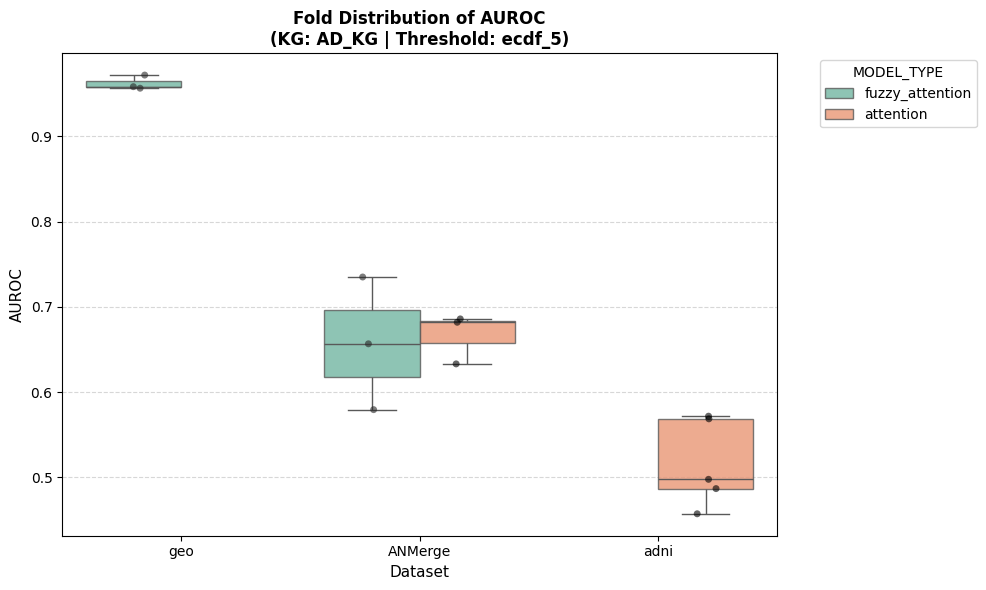

Plot saved successfully as 'boxplot_AUROC.png'


/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_60675/74606162.py:105: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


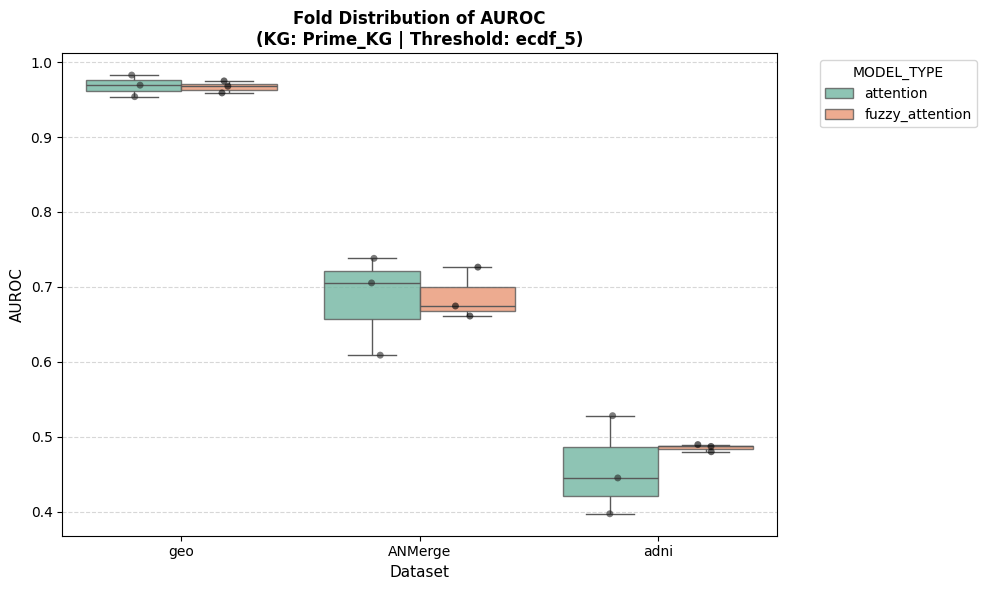

Plot saved successfully as 'boxplot_AUROC.png'


/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_60675/74606162.py:105: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


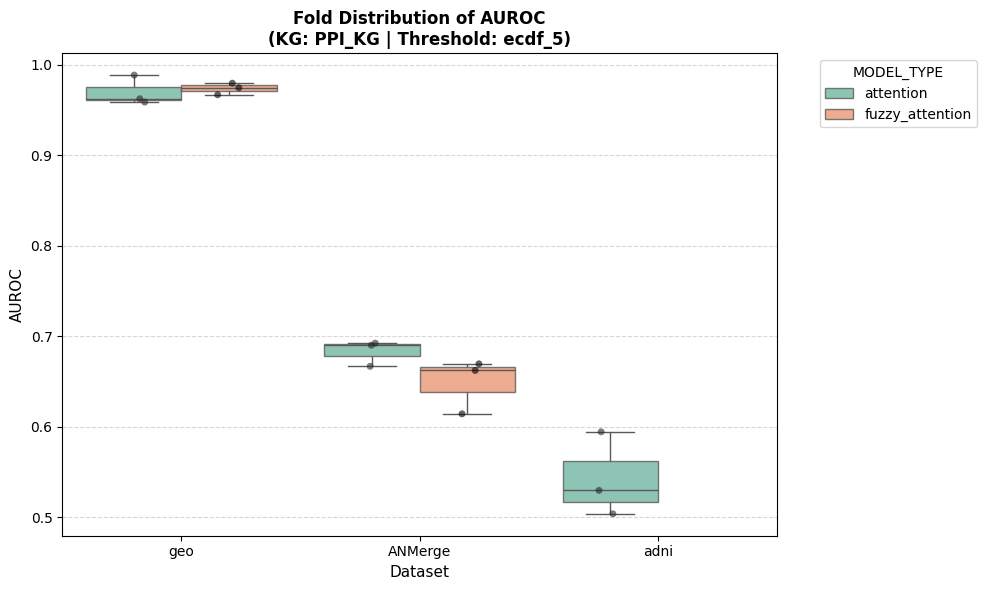

Plot saved successfully as 'boxplot_AUROC.png'


/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_60675/74606162.py:105: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


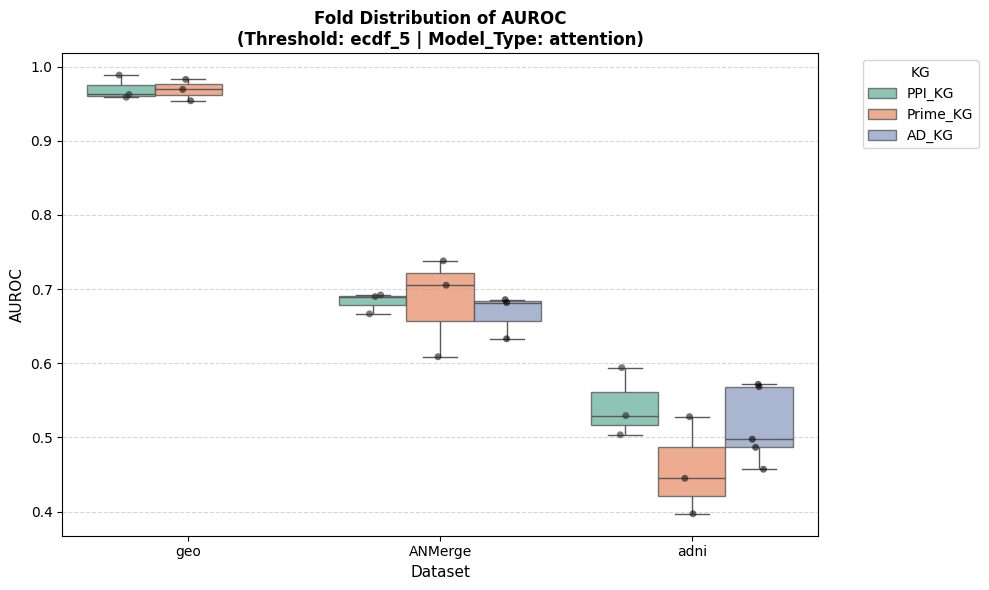

Plot saved successfully as 'boxplot_AUROC.png'


/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_60675/74606162.py:105: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


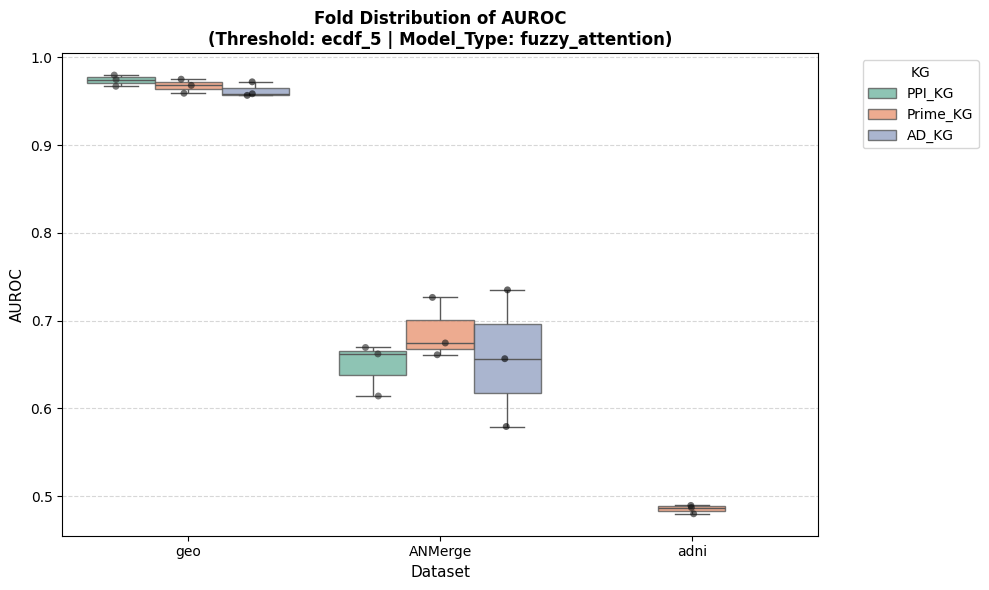

Plot saved successfully as 'boxplot_AUROC.png'


In [78]:
root_dir = "./results/aggregator2"
df = parse_cv_metrics(root_dir)
plot_fold_metric_comparison(df, 
                                metric_name='AUROC', 
                                kg='AD_KG', 
                                scoring_method='ecdf_5', 
                                model_type=None,
                                hue='model_type')
plot_fold_metric_comparison(df, 
                                metric_name='AUROC', 
                                kg='Prime_KG', 
                                scoring_method='ecdf_5', 
                                model_type=None,
                                hue='model_type')
plot_fold_metric_comparison(df, 
                                metric_name='AUROC', 
                                kg='PPI_KG', 
                                scoring_method='ecdf_5', 
                                model_type=None,
                                hue='model_type')

plot_fold_metric_comparison(df, 
                                metric_name='AUROC', 
                                kg=None, 
                                scoring_method='ecdf_5', 
                                model_type='attention',
                                hue='kg')
plot_fold_metric_comparison(df, 
                                metric_name='AUROC', 
                                kg=None, 
                                scoring_method='ecdf_5', 
                                model_type='fuzzy_attention',
                                hue='kg')

#### CV Retrain
+ fuzzy attention: 
  + not inlcude 2-hop label agreement (label homophily)
  + topo features: 
    + degree, 
    + degree centraility, 
    + average_neighbor_degrees
    + average edge weight
    + edge_type attentions

/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_60675/74606162.py:105: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


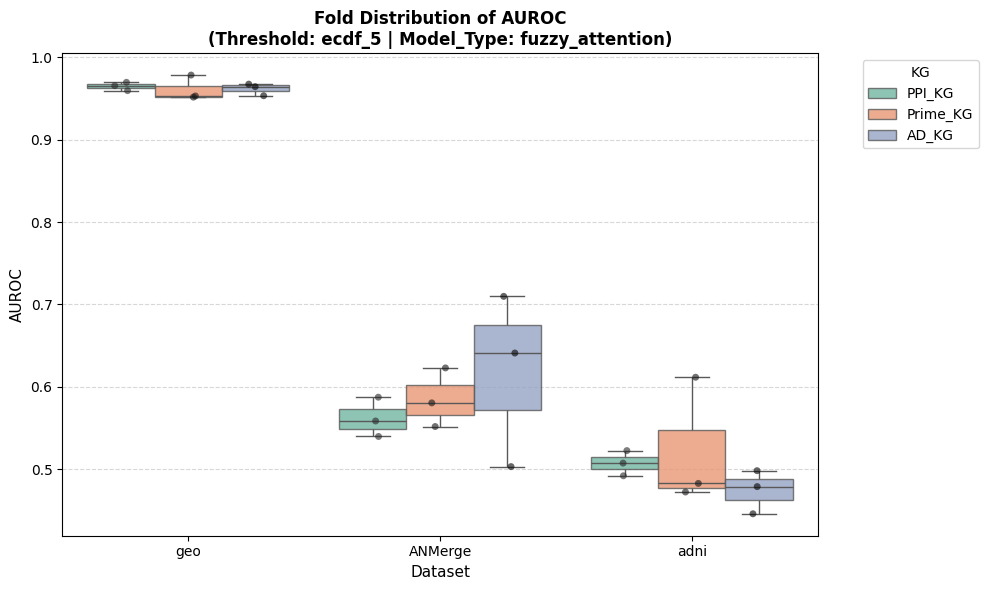

Plot saved successfully as 'boxplot_AUROC.png'


In [70]:
root_dir = "./results/aggregator3"
df = parse_cv_metrics(root_dir)

plot_fold_metric_comparison(df, 
                                metric_name='AUROC', 
                                kg=None, 
                                scoring_method='ecdf_5', 
                                model_type='fuzzy_attention',
                                hue='kg')

#### label homophily
+ fuzzy attention: 
  + inlcude 2-hop label agreement (label homophily)
  + topo features: 
    + degree, 
    + degree centraility, 
    + average_neighbor_degrees
    + average edge weight
    + 2-hop label aggrement
    + edge_type attentions

/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_60675/74606162.py:105: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


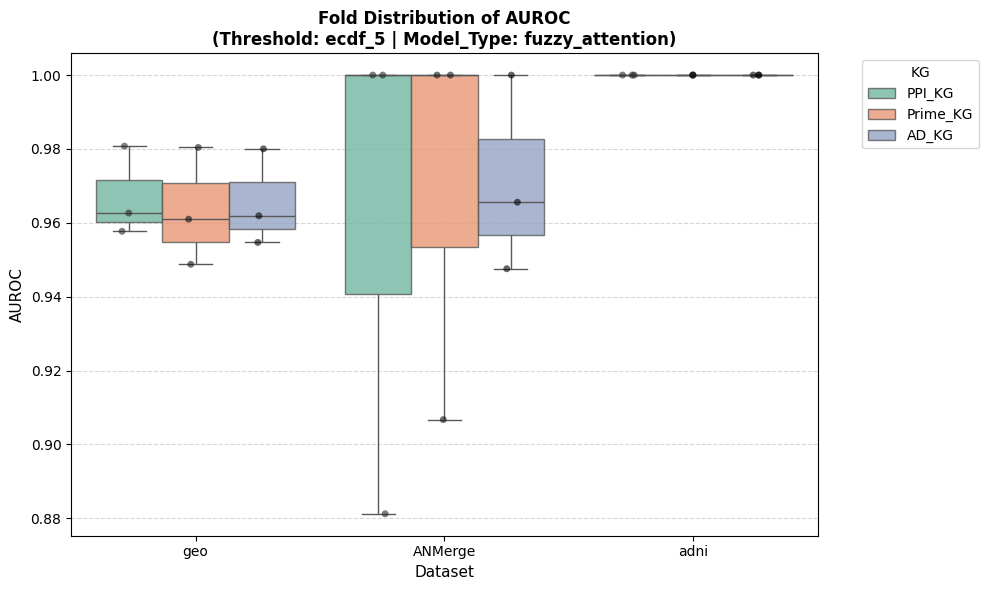

Plot saved successfully as 'boxplot_AUROC.png'


In [72]:
root_dir = "./results/label_homophily"
df = parse_cv_metrics(root_dir)

plot_fold_metric_comparison(df, 
                                metric_name='AUROC', 
                                kg=None, 
                                scoring_method='ecdf_5', 
                                model_type='fuzzy_attention',
                                hue='kg')

/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_60675/74606162.py:105: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


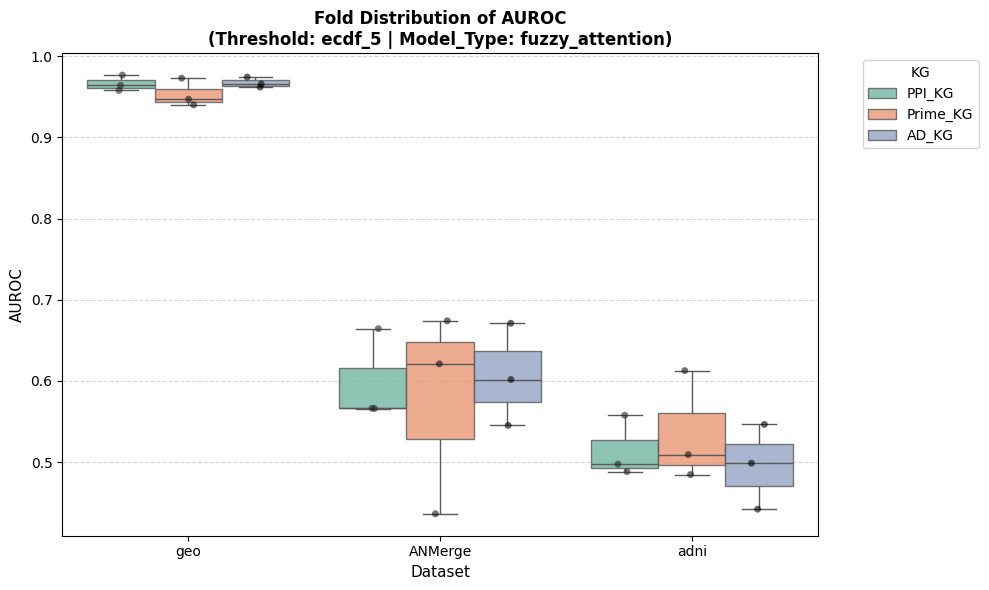

Plot saved successfully as 'boxplot_AUROC.png'


In [76]:
root_dir = "../../EdgeAssignmentTask/gumbel_softmax/results/no_label_homophily"
df = parse_cv_metrics(root_dir)

plot_fold_metric_comparison(df, 
                                metric_name='AUROC', 
                                kg=None, 
                                scoring_method='ecdf_5', 
                                model_type='fuzzy_attention',
                                hue='kg')

/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_60675/74606162.py:105: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


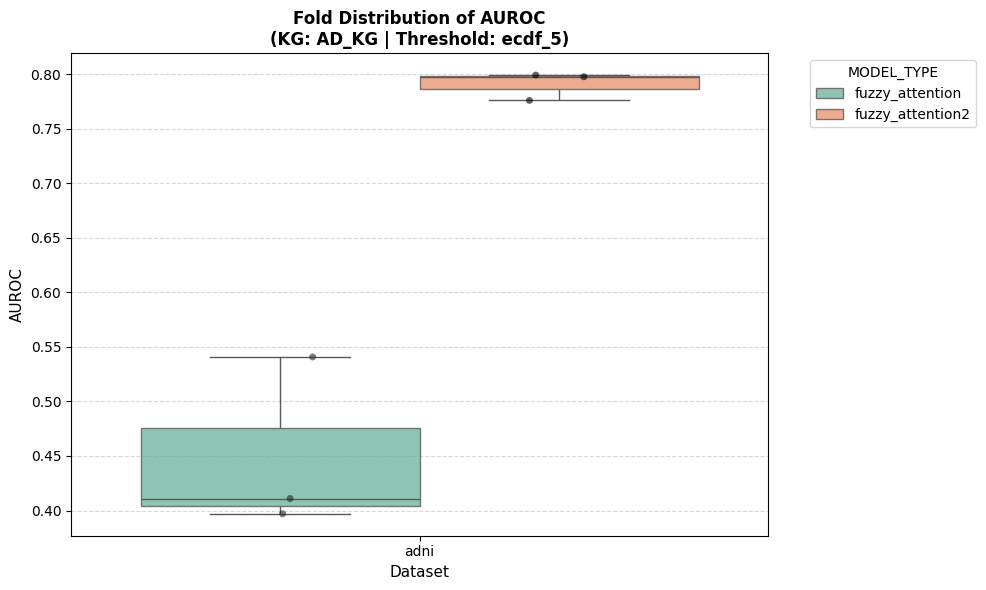

Plot saved successfully as 'boxplot_AUROC.png'


/var/folders/ft/2nftg5q91n5dhpf5dtts4gkm0000gn/T/ipykernel_60675/74606162.py:105: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


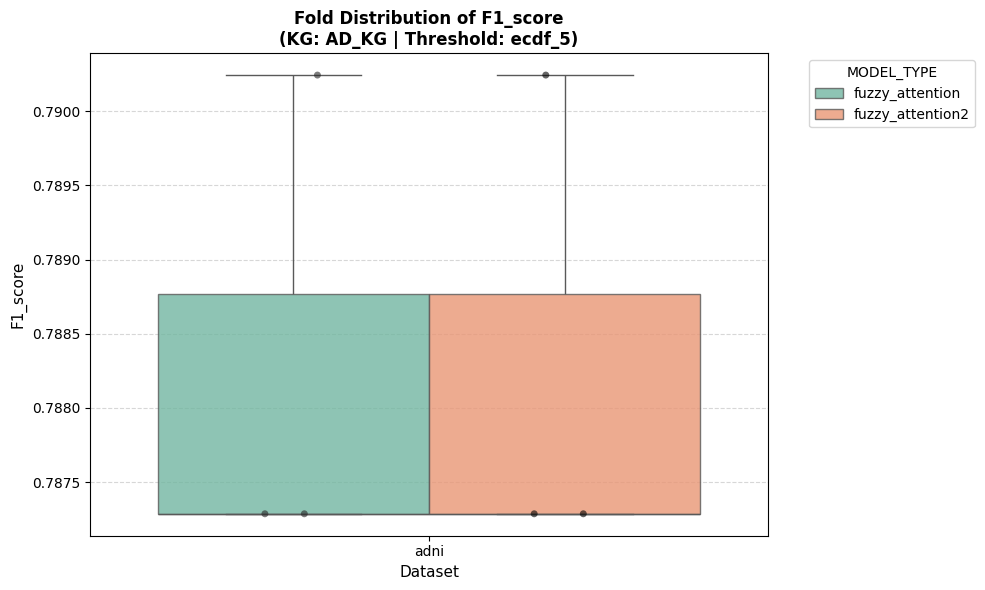

Plot saved successfully as 'boxplot_F1_score.png'


In [83]:
root_dir = "../../EdgeAssignmentTask/gumbel_softmax/results/fuzzy_features"
df = parse_cv_metrics(root_dir)

plot_fold_metric_comparison(df, 
                                metric_name='AUROC', 
                                kg='AD_KG', 
                                scoring_method='ecdf_5', 
                                model_type=None,
                                hue='model_type')

plot_fold_metric_comparison(df, 
                                metric_name='F1_score', 
                                kg='AD_KG', 
                                scoring_method='ecdf_5', 
                                model_type=None,
                                hue='model_type')

In [80]:
df

""
